# Task 1: Predicting House Prices with Linear Regression

**Objective:** build and evaluate a linear regression model that predicts house price from features like area, location, rooms and age, going step by step from data cleaning to model interpretation.

**Tech stack:** Python, pandas, scikit-learn, matplotlib, seaborn

**Dataset:** `House_Price_Prediction_Dataset.csv` (2000 houses, 10 columns)

## 1. Importing libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

## 2. Loading the data

In [2]:
df = pd.read_csv("House_Price_Prediction_Dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (2000, 10)


   Id  Area  Bedrooms  Bathrooms  ...  Location  Condition Garage   Price
0   1  1360         5          4  ...  Downtown  Excellent     No  149919
1   2  4272         5          4  ...  Downtown  Excellent     No  424998
2   3  3592         2          2  ...  Downtown       Good     No  266746
3   4   966         4          2  ...  Suburban       Fair    Yes  244020
4   5  4926         1          4  ...  Downtown       Fair    Yes  636056

[5 rows x 10 columns]

## 3. Exploratory Data Analysis (EDA)

First the basics: data types, null values, duplicates and descriptive statistics.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 156.4 KB


In [4]:
# null check and duplicate check
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

Duplicate rows: 0


In [5]:
# descriptive statistics of the numeric columns
df.describe().T.round(2)

            count       mean        std  ...       50%        75%       max
Id         2000.0    1000.50     577.49  ...    1000.5    1500.25    2000.0
Area       2000.0    2786.21    1295.15  ...    2833.0    3887.50    4999.0
Bedrooms   2000.0       3.00       1.42  ...       3.0       4.00       5.0
Bathrooms  2000.0       2.55       1.11  ...       3.0       4.00       4.0
Floors     2000.0       1.99       0.81  ...       2.0       3.00       3.0
YearBuilt  2000.0    1961.45      35.93  ...    1961.0    1993.00    2023.0
Price      2000.0  537676.86  276428.85  ...  539254.0  780086.00  999656.0

[7 rows x 8 columns]

In [6]:
# categorical columns
for col in ["Location", "Condition", "Garage"]:
    print(df[col].value_counts(), "\n")

Location
Downtown    558
Urban       485
Suburban    483
Rural       474
Name: count, dtype: int64 

Condition
Fair         521
Excellent    511
Poor         507
Good         461
Name: count, dtype: int64 

Garage
No     1038
Yes     962
Name: count, dtype: int64 



**What I noticed:**
- There are **no missing values and no duplicate rows**, so the data is already clean.
- `Id` is just a row number, so it carries no information and will be dropped.
- `Bedrooms` (1 to 5), `Bathrooms` (1 to 4) and `Floors` (1 to 3) have only a few distinct values, and each value appears almost equally often. Real housing data is usually not this evenly spread.
- The three categorical columns (`Location`, `Condition`, `Garage`) are also very balanced.

### 3.1 Distribution of the target variable (Price)

Min: 50005 | Max: 999656
Skewness: -0.064
Kurtosis: -1.203


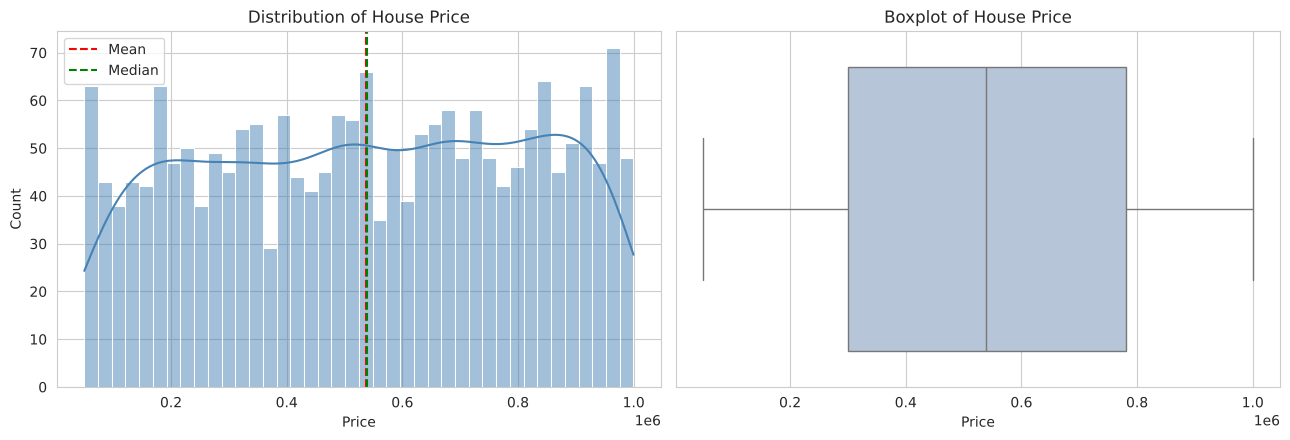

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df["Price"], bins=40, kde=True, color="steelblue", ax=ax[0])
ax[0].axvline(df["Price"].mean(), color="red", linestyle="--", label="Mean")
ax[0].axvline(df["Price"].median(), color="green", linestyle="--", label="Median")
ax[0].set_title("Distribution of House Price")
ax[0].set_xlabel("Price")
ax[0].legend()

sns.boxplot(x=df["Price"], color="lightsteelblue", ax=ax[1])
ax[1].set_title("Boxplot of House Price")
ax[1].set_xlabel("Price")

plt.tight_layout()
plt.show()

print("Min:", df["Price"].min(), "| Max:", df["Price"].max())
print("Skewness:", round(df["Price"].skew(), 3))
print("Kurtosis:", round(df["Price"].kurt(), 3))

**Insight:**
- Prices run from about 50,000 to 1,000,000, with a mean of roughly 538k.
- Mean and median are almost the same and skewness is close to 0, so there is **no right skew** like we usually see in house prices. No log transform is needed.
- The histogram is **flat** (kurtosis is about -1.2) rather than bell shaped, which is what a uniform spread looks like. There are also no outliers in the boxplot.

### 3.2 How does Price vary with each feature?

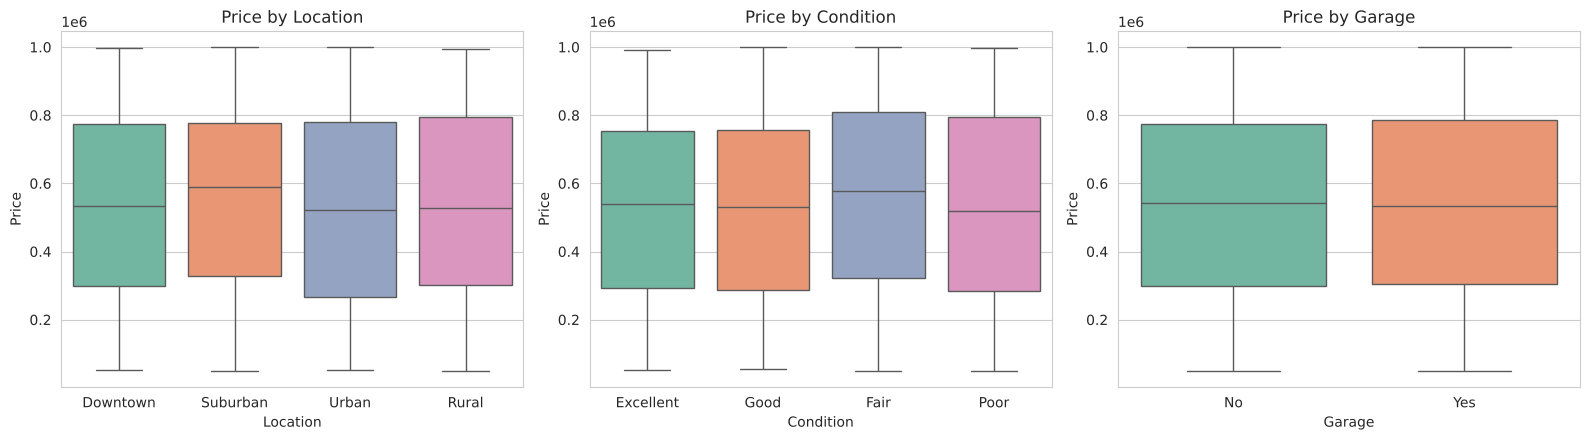

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col in zip(ax, ["Location", "Condition", "Garage"]):
    sns.boxplot(data=df, x=col, y="Price", palette="Set2", ax=a)
    a.set_title(f"Price by {col}")
plt.tight_layout()
plt.show()

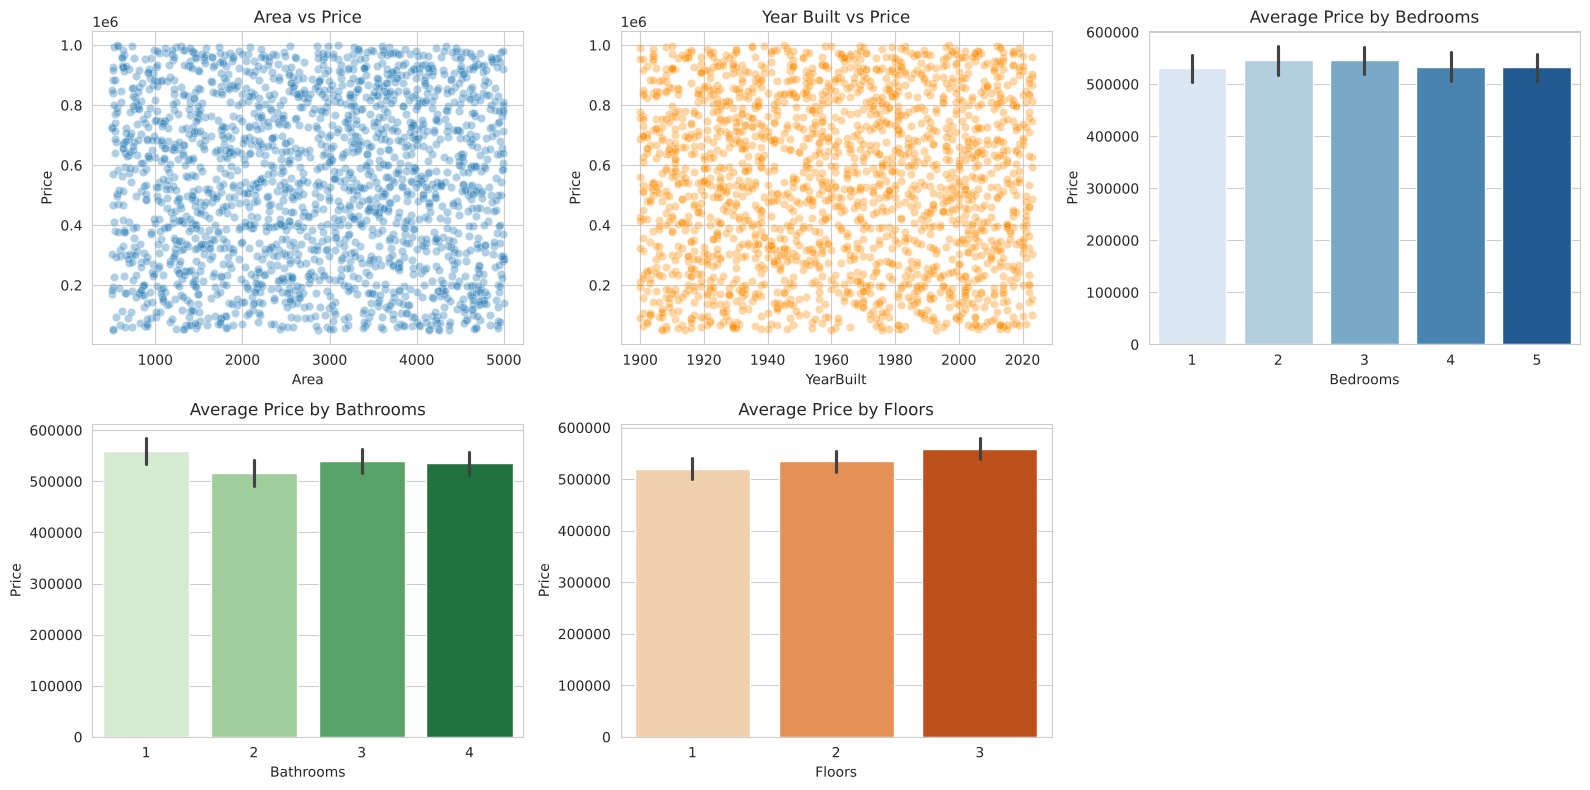

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
ax = ax.flatten()

sns.scatterplot(data=df, x="Area", y="Price", alpha=0.35, ax=ax[0])
ax[0].set_title("Area vs Price")
sns.scatterplot(data=df, x="YearBuilt", y="Price", alpha=0.35, ax=ax[1], color="darkorange")
ax[1].set_title("Year Built vs Price")
sns.barplot(data=df, x="Bedrooms", y="Price", ax=ax[2], palette="Blues")
ax[2].set_title("Average Price by Bedrooms")
sns.barplot(data=df, x="Bathrooms", y="Price", ax=ax[3], palette="Greens")
ax[3].set_title("Average Price by Bathrooms")
sns.barplot(data=df, x="Floors", y="Price", ax=ax[4], palette="Oranges")
ax[4].set_title("Average Price by Floors")
ax[5].axis("off")

plt.tight_layout()
plt.show()

In [10]:
# average and median price per category, to compare the groups numerically
for col in ["Location", "Condition", "Garage"]:
    print(df.groupby(col)["Price"].agg(["mean", "median", "count"]).round(0), "\n")

              mean    median  count
Location                           
Downtown  536060.0  532340.0    558
Rural     538614.0  527560.0    474
Suburban  557416.0  589618.0    483
Urban     518964.0  520917.0    485 

               mean    median  count
Condition                           
Excellent  530812.0  540339.0    511
Fair       560594.0  577800.0    521
Good       529002.0  529898.0    461
Poor       528933.0  518304.0    507 

            mean    median  count
Garage                           
No      536921.0  542866.0   1038
Yes     538493.0  533877.0    962 



**Insight:**
- The boxplots for every category look almost identical. A `Downtown` house is not clearly more expensive than a `Rural` one, and an `Excellent` condition house is not more expensive than a `Poor` one.
- The Area vs Price scatter is a **shapeless cloud**: a 1000 sq ft house and a 5000 sq ft house can have the same price.
- Group averages differ only by a few percent. For example, the `Suburban` average is about 557k while `Urban` is about 519k, which is a small gap compared with the spread inside each group (std is around 275k).

This is already a warning sign that none of these features has a strong relationship with price. We will check this properly with correlations and the model.

## 4. Feature selection discussion

Before looking at any numbers I wrote down which features I would expect to drive the price, based on how the housing market usually works:

| Feature | Expected effect | Reasoning |
|---|---|---|
| **Area** | Strong positive | Bigger houses cost more. Usually the single best predictor. |
| **Location** | Strong | Downtown / Urban areas normally cost more than Rural because of demand and access to facilities. |
| **Bathrooms, Bedrooms** | Positive | More rooms means a bigger and more usable house. Area already captures part of this, so there may be overlap (multicollinearity). |
| **Floors** | Mild positive | Multi-storey houses have more built-up space. |
| **Condition** | Positive | A house in Excellent condition should sell for more than one in Poor condition. |
| **Garage** | Mild positive | Parking is a premium feature, especially in dense areas. |
| **YearBuilt** | Weak / unclear | Newer houses are generally more valuable, but old heritage houses can also be expensive. I convert it to `HouseAge` since age is easier to interpret. |
| **Id** | None | Just a row identifier, so it is dropped. |

So my hypothesis is that Area, Location and Condition would be the top predictors. The next sections test whether the data agrees.

## 5. Data preparation

- **Missing values:** the null check showed none, but I still keep a small safety step (median for numbers, mode for text) so the code works if the dataset is replaced with a messier version.
- **Feature engineering:** `YearBuilt` is converted into `HouseAge` (2026 minus year built).
- **Encoding:** `Location`, `Condition` and `Garage` are one-hot encoded. I use `drop_first=True` so each category group has one reference level, which avoids the dummy variable trap (perfect multicollinearity) in linear regression.

In [11]:
data = df.copy()

# safety net for missing values (nothing gets filled in this dataset)
for col in data.columns:
    if data[col].isnull().any():
        if data[col].dtype == "object":
            data[col] = data[col].fillna(data[col].mode()[0])
        else:
            data[col] = data[col].fillna(data[col].median())

# house age instead of build year
data["HouseAge"] = 2026 - data["YearBuilt"]

# drop columns we don't need
data = data.drop(columns=["Id", "YearBuilt"])

# one-hot encoding of categorical features
data = pd.get_dummies(data, columns=["Location", "Condition", "Garage"], drop_first=True, dtype=int)

print("Shape after encoding:", data.shape)
data.head()

Shape after encoding: (2000, 13)


   Area  Bedrooms  Bathrooms  ...  Condition_Good  Condition_Poor  Garage_Yes
0  1360         5          4  ...               0               0           0
1  4272         5          4  ...               0               0           0
2  3592         2          2  ...               1               0           0
3   966         4          2  ...               0               0           1
4  4926         1          4  ...               0               0           1

[5 rows x 13 columns]

Reference categories after `drop_first=True`: **Location = Downtown**, **Condition = Excellent**, **Garage = No**. Every dummy coefficient later is read relative to these.

## 6. Correlation analysis

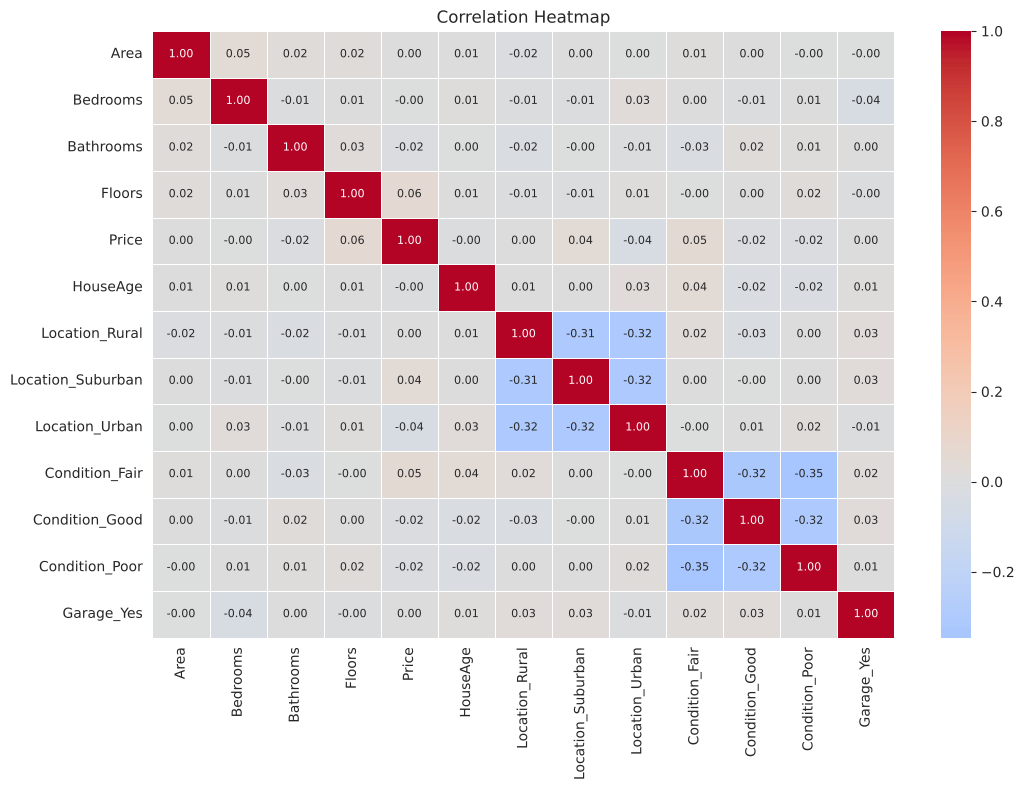

In [12]:
plt.figure(figsize=(11, 8))
corr_matrix = data.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, annot_kws={"size": 8})
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Location_Urban      -0.0383
Condition_Poor      -0.0184
Condition_Good      -0.0172
Bathrooms           -0.0157
HouseAge            -0.0048
Bedrooms            -0.0035
Area                 0.0015
Location_Rural       0.0019
Garage_Yes           0.0028
Location_Suburban    0.0403
Condition_Fair       0.0492
Floors               0.0559
Name: Price, dtype: float64


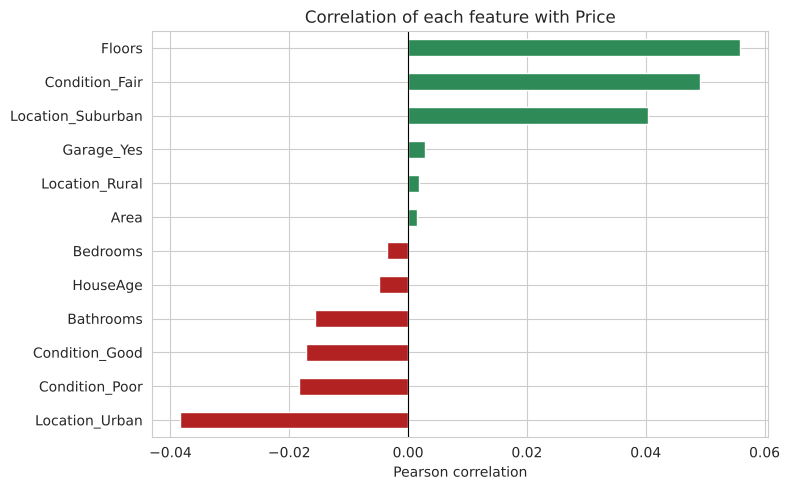

In [13]:
# correlation of every feature with Price, sorted
price_corr = corr_matrix["Price"].drop("Price").sort_values()

plt.figure(figsize=(8, 5))
colors = ["firebrick" if v < 0 else "seagreen" for v in price_corr]
price_corr.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation of each feature with Price")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

print(price_corr.round(4))

**Insight:**
- Every correlation with `Price` is tiny. The strongest ones are `Floors` (+0.056), `Condition_Fair` (+0.049), `Location_Suburban` (+0.040) and `Location_Urban` (-0.038). Anything below about 0.1 is practically no linear relationship.
- `Area` has a correlation of just **0.0015** with price, which is surprising because it is normally the strongest feature.
- Features are also not correlated with each other (the heatmap is almost blank), so **multicollinearity is not a problem** here. Bedrooms and Bathrooms are not tied to Area either.
- In short, no feature stands out as a good predictor, so I expect the model to struggle. Let's confirm by building it.

## 7. Train / test split (80/20)

In [14]:
X = data.drop(columns=["Price"])
y = data["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set:", X_train.shape)
print("Test set    :", X_test.shape)

Training set: (1600, 12)
Test set    : (400, 12)


## 8. Training the Linear Regression model

In [15]:
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)
print("Model trained. Intercept:", round(lr.intercept_, 2))

Model trained. Intercept: 516806.26


## 9. Model evaluation

Metrics used: MSE, RMSE and R². I also add MAE, and a **baseline model** that always predicts the average training price. A model is only useful if it beats this baseline.

In [16]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# baseline: predict the mean price for every house
baseline_pred = np.full(len(y_test), y_train.mean())
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

print(f"MSE  : {mse:,.0f}")
print(f"RMSE : {rmse:,.0f}")
print(f"MAE  : {mae:,.0f}")
print(f"R2   : {r2:.4f}")
print(f"\nTrain R2        : {lr.score(X_train, y_train):.4f}")
print(f"Baseline RMSE   : {baseline_rmse:,.0f}  (always predicting the mean price)")

MSE  : 78,321,466,146
RMSE : 279,860
MAE  : 243,242
R2   : -0.0067

Train R2        : 0.0099
Baseline RMSE   : 279,024  (always predicting the mean price)


In [17]:
# 5-fold cross validation to make sure this isn't just a bad luck split
cv_scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print("CV R2 scores:", cv_scores.round(4))
print("Mean CV R2  :", round(cv_scores.mean(), 4))

CV R2 scores: [-0.0045 -0.0109 -0.0313 -0.0004  0.0059]
Mean CV R2  : -0.0083


**Insight:**
- Test **R² is about -0.007** and RMSE is about **280k**, which is essentially the same as the baseline RMSE (about 279k). So the model is **no better than just guessing the average price** for every house.
- An R² near 0 means the features explain almost none of the variation in price. A slightly negative value just means it does slightly worse than the mean on unseen data.
- The train R² is only about 0.01, so this is **not overfitting**. The model has nothing to overfit to. It is also not underfitting because of a wrong model type (I check that again with a random forest below).
- Cross validation gives the same story (scores hover around 0), so the result does not depend on the particular 80/20 split.
- An RMSE of 280k on prices that average 538k is a very large error (about 52%), so this model could not be used to price a real house.

## 10. Actual vs Predicted prices

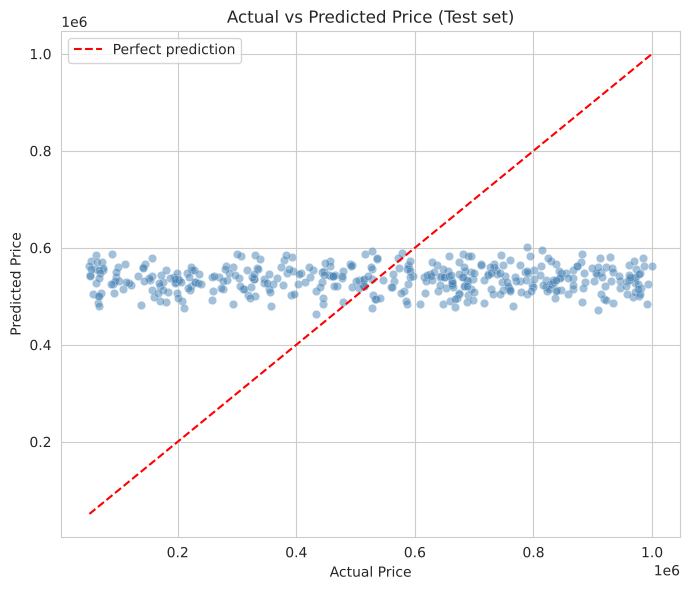

In [18]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color="steelblue", edgecolor="white", linewidth=0.3)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price (Test set)")
plt.legend()
plt.tight_layout()
plt.show()

**Insight:** For a good model the points should hug the red diagonal. Here the predictions are squeezed into a **narrow horizontal band** (roughly 460k to 600k) while actual prices range from 50k to 1M. The model basically predicts "about average" for every house, which matches the R² of ~0.

## 11. Residual analysis

Mean of residuals: 8623.22


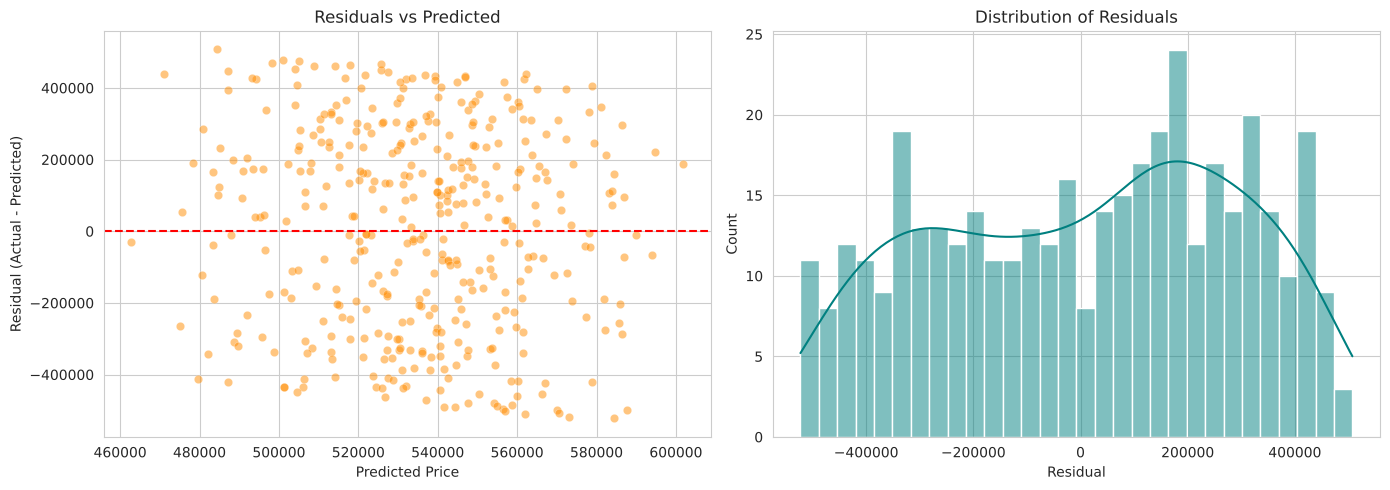

In [19]:
residuals = y_test - y_pred

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(y_pred, residuals, alpha=0.5, color="darkorange", edgecolor="white", linewidth=0.3)
ax[0].axhline(0, color="red", linestyle="--")
ax[0].set_xlabel("Predicted Price")
ax[0].set_ylabel("Residual (Actual - Predicted)")
ax[0].set_title("Residuals vs Predicted")

sns.histplot(residuals, bins=30, kde=True, color="teal", ax=ax[1])
ax[1].set_title("Distribution of Residuals")
ax[1].set_xlabel("Residual")

plt.tight_layout()
plt.show()

print("Mean of residuals:", round(residuals.mean(), 2))

**Insight:**
- The residuals are scattered evenly around zero with **no curve, funnel or other systematic pattern**, and the mean is only about 9k, small next to the 280k spread. On the surface this passes the usual residual check (no heteroscedasticity, no obvious non-linearity).
- But this needs a careful reading. The residuals look "random" because the model captured almost nothing, so the residuals are just the original price spread (flat, from about -500k to +500k) shifted around zero. Their histogram is wide and flat, not bell shaped, which mirrors the uniform price distribution.
- So a random-looking residual plot does not mean a good model here. It should be read together with R² and RMSE.

## 12. Coefficient analysis

In [20]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr.coef_,
    # impact of a 1 standard deviation change, so features on different scales can be compared fairly
    "Impact_per_1_std": lr.coef_ * X.std().values
}).sort_values("Coefficient", ascending=False).reset_index(drop=True)

coef_df.round(2)

              Feature  Coefficient  Impact_per_1_std
0      Condition_Fair     24083.31          10572.99
1              Floors     23727.98          19200.40
2   Location_Suburban     11511.99           4928.28
3      Condition_Poor      4073.27           1772.37
4          Garage_Yes      2373.53           1186.20
5      Location_Rural      1317.54            560.41
6            Bedrooms        76.78            109.39
7                Area        -0.58           -745.69
8            HouseAge      -117.61          -4225.48
9           Bathrooms     -9662.25         -10715.34
10     Location_Urban    -12718.92          -5452.63
11     Condition_Good    -12941.04          -5451.52

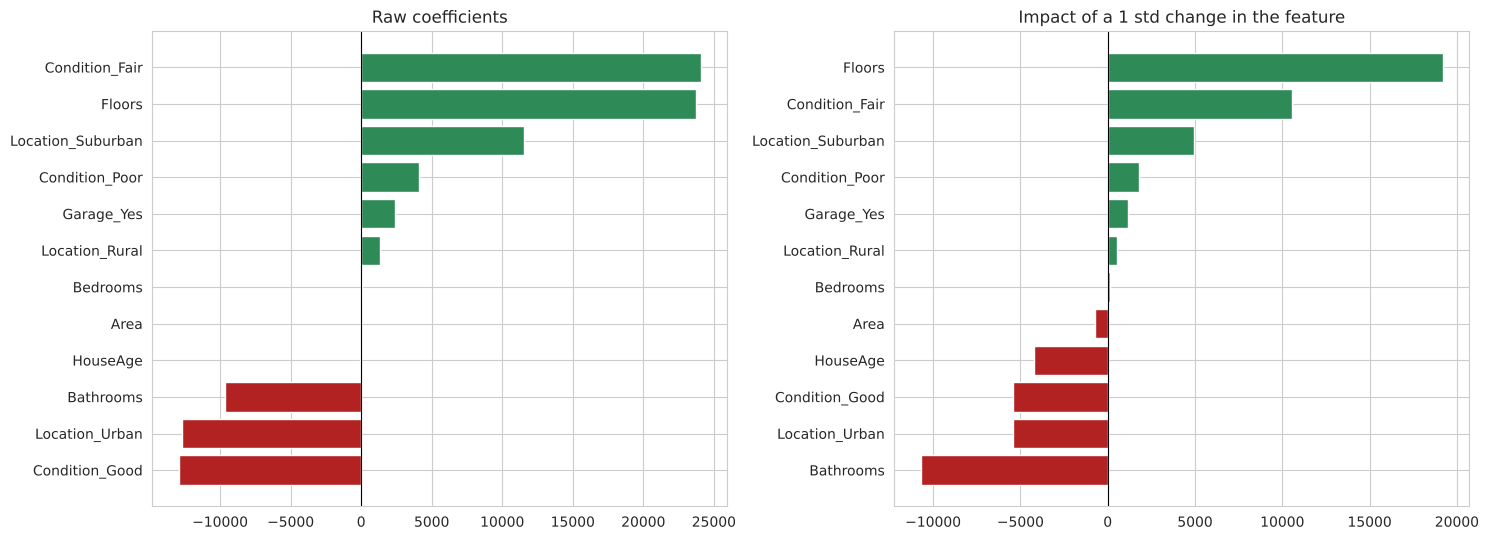

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

c1 = coef_df.sort_values("Coefficient")
ax[0].barh(c1["Feature"], c1["Coefficient"], color=["firebrick" if v < 0 else "seagreen" for v in c1["Coefficient"]])
ax[0].axvline(0, color="black", linewidth=0.8)
ax[0].set_title("Raw coefficients")

c2 = coef_df.sort_values("Impact_per_1_std")
ax[1].barh(c2["Feature"], c2["Impact_per_1_std"], color=["firebrick" if v < 0 else "seagreen" for v in c2["Impact_per_1_std"]])
ax[1].axvline(0, color="black", linewidth=0.8)
ax[1].set_title("Impact of a 1 std change in the feature")

plt.tight_layout()
plt.show()

**Insight:**
- **Highest positive impact:** `Condition_Fair` (about +24k vs Excellent), `Floors` (about +24k per extra floor) and `Location_Suburban` (about +12k vs Downtown).
- **Highest negative impact:** `Condition_Good` (about -13k vs Excellent), `Location_Urban` (about -13k vs Downtown) and `Bathrooms` (about -10k per extra bathroom).
- Many of these signs **do not make sense** in the real world. A house in "Fair" condition should not sell for 24k more than an "Excellent" one, and more bathrooms should not reduce the price. `Area` has a coefficient of about -0.58, which would mean each extra square foot slightly *lowers* the price.
- The reason is that the model is just fitting noise. These coefficients are small compared to the price spread (std about 276k) and are not reliable. They should not be interpreted as real effects.

## 13. (Bonus) Ridge and Lasso regularisation

Regularisation shrinks coefficients to reduce overfitting. Lasso can also push useless coefficients to exactly zero, which acts as automatic feature selection. The features are scaled first (required for regularised models) and the regularisation strength (alpha) is chosen by cross validation.

In [22]:
alphas_ridge = np.logspace(-2, 3, 30)
alphas_lasso = np.logspace(0, 4, 30)

ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas_ridge)).fit(X_train, y_train)
lasso = make_pipeline(StandardScaler(), LassoCV(alphas=alphas_lasso, cv=5, max_iter=50000)).fit(X_train, y_train)
ols_scaled = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)

results = []
for name, model in [("Linear Regression", ols_scaled), ("Ridge", ridge), ("Lasso", lasso)]:
    p = model.predict(X_test)
    results.append({
        "Model": name,
        "MSE": mean_squared_error(y_test, p),
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "R2": r2_score(y_test, p)
    })

results_df = pd.DataFrame(results).set_index("Model")
print("Best Ridge alpha:", round(ridge[-1].alpha_, 2))
print("Best Lasso alpha:", round(lasso[-1].alpha_, 2))
results_df.round(4)

Best Ridge alpha: 1000.0
Best Lasso alpha: 7278.95


                            MSE         RMSE      R2
Model                                               
Linear Regression  7.832147e+10  279859.7258 -0.0067
Ridge              7.796190e+10  279216.5887 -0.0021
Lasso              7.797900e+10  279247.2090 -0.0023

In [23]:
# coefficients side by side (on scaled features)
coef_compare = pd.DataFrame({
    "Linear": ols_scaled[-1].coef_,
    "Ridge": ridge[-1].coef_,
    "Lasso": lasso[-1].coef_
}, index=X.columns).round(0)

coef_compare

                    Linear    Ridge    Lasso
Area                -749.0   -351.0     -0.0
Bedrooms             110.0     43.0     -0.0
Bathrooms         -10714.0  -6591.0  -3577.0
Floors             19148.0  11708.0  11482.0
HouseAge           -4223.0  -2560.0     -0.0
Location_Rural       565.0    517.0      0.0
Location_Suburban   4858.0   3297.0      0.0
Location_Urban     -5484.0  -3626.0     -0.0
Condition_Fair     10621.0   6576.0   4689.0
Condition_Good     -5441.0  -4512.0   -897.0
Condition_Poor      1778.0    410.0      0.0
Garage_Yes          1185.0    687.0      0.0

**Insight:**
- Ridge and Lasso both give RMSE about 279k and R² about -0.002, a **tiny improvement** over plain linear regression (R² about -0.007) but still essentially zero.
- The cross validation picked very large alpha values (Ridge: 1000, the top of the range I searched; Lasso: about 7279). Ridge hit the top of the alpha range I searched, and both models want heavy shrinkage, which is a sign that they prefer to ignore the features.
- Lasso set **8 of the 12 coefficients to exactly zero** and kept only `Floors`, `Condition_Fair`, `Bathrooms` and `Condition_Good`, with small values. Even Lasso is telling us that almost nothing in this data is useful for predicting price.

## 14. Extra check: is it a linear model problem?

Linear regression can only find straight line relationships. To make sure the poor result is not just because the relationship is non-linear, I try a random forest, which can capture curves and interactions between features.

In [24]:
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=20, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print(f"Random Forest R2   : {r2_score(y_test, rf_pred):.4f}")
print(f"Random Forest RMSE : {np.sqrt(mean_squared_error(y_test, rf_pred)):,.0f}")

Random Forest R2   : -0.0188
Random Forest RMSE : 281,541


The random forest also gets an R² of about 0 (slightly negative), so even a model that can capture non-linear patterns finds nothing. The problem is the **data**, not the choice of linear regression.

## 15. Final conclusion

**What I did:** cleaned and explored the data, one-hot encoded the categorical features, checked correlations, trained a linear regression on an 80/20 split, evaluated it with MSE, RMSE and R², checked the residuals, interpreted the coefficients and compared it with Ridge and Lasso.

**Results summary**

| Model | RMSE | R² |
|---|---|---|
| Baseline (always predict mean) | about 279k | 0 |
| Linear Regression | about 280k | about -0.007 |
| Ridge | about 279k | about -0.002 |
| Lasso | about 279k | about -0.002 |
| Random Forest (extra check) | about 280k | about -0.02 |

**Key findings**
1. The pipeline works correctly (no nulls, proper encoding, no leakage, proper train/test split), but the **model has essentially no predictive power**. R² is about 0 and it does no better than predicting the average price.
2. Contrary to my initial hypothesis, **Area, Location and Condition are not predictors** in this dataset. Their correlation with price is almost zero.
3. Prices are spread evenly between 50k and 1M and look **independent of the features**. Together with the very even spread of rooms, floors, locations and conditions, this suggests the dataset is synthetic (randomly generated), so there is no real signal to learn.
4. The coefficients have counter-intuitive signs (for example a negative effect for Area and Bathrooms), so they should be treated as noise and not as real effects.
5. Regularisation (Ridge / Lasso) and a non-linear model (random forest) did not help either, which confirms the issue is the data and not the algorithm.

**Limitations and next steps**
- With real data, I would expect Area, Location and Condition to matter, and the same pipeline could be reused directly. A well known option is the Ames Housing dataset from Kaggle.
- Useful extra features would be neighbourhood or pin code, distance to the city centre, schools and transport, and the sale date.
- If the price has a skewed distribution in real data, a log transform of `Price` usually helps linear regression.